# Análisis exploratorio de incidencia delictiva en México

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
df = pd.read_csv('data/delitos.csv')

#### Ejercicio 1: Elige 3 estados de la república y grafica una serie de tiempo de la frecuencia abosluta de homicidios dolosos de enero 2015 a julio 2019 en estas tres entidades

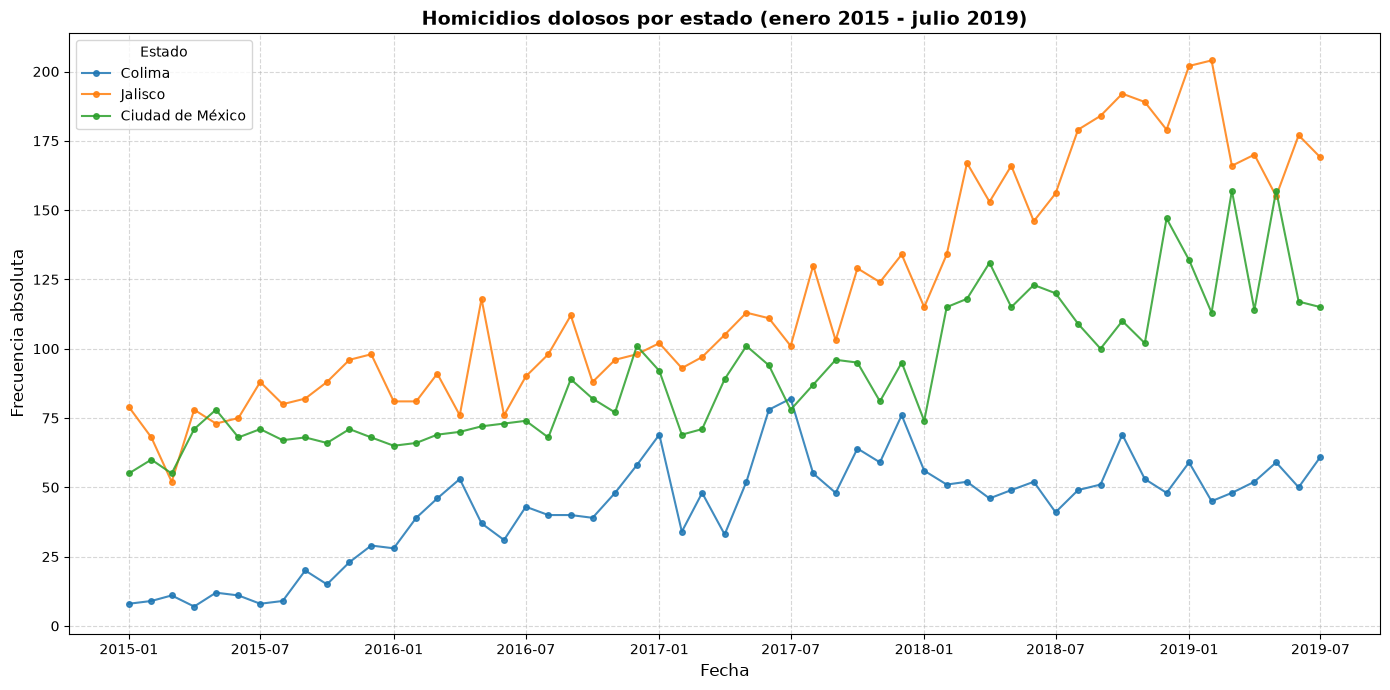

In [3]:
# Ejercicio 1: serie de tiempo de homicidios dolosos en 3 estados (2015-01 a 2019-07)
# Usamos el archivo original porque conserva la columna "Subtipo de delito".
datos_originales = pd.read_csv('data/datos_delitos.csv', encoding='ISO-8859-1')
columnas_meses = [
    'Enero', 'Febrero', 'Marzo', 'Abril', 'Mayo', 'Junio',
    'Julio', 'Agosto', 'Septiembre', 'Octubre', 'Noviembre', 'Diciembre'
]
numero_mes = {mes: numero for numero, mes in enumerate(columnas_meses, start=1)}

homicidios_dolosos = datos_originales[
    datos_originales['Subtipo de delito'] == 'Homicidio doloso'
].melt(
    id_vars=['Año', 'Clave_Ent', 'Entidad'],
    value_vars=columnas_meses,
    var_name='Mes',
    value_name='Frecuencia'
)
homicidios_dolosos['Fecha'] = pd.to_datetime({
    'year': homicidios_dolosos['Año'],
    'month': homicidios_dolosos['Mes'].map(numero_mes),
    'day': 1
})

estados_elegidos = ['Colima', 'Jalisco', 'Ciudad de México']
serie_homicidios = (
    homicidios_dolosos[
        homicidios_dolosos['Entidad'].isin(estados_elegidos)
        & homicidios_dolosos['Fecha'].between('2015-01-01', '2019-07-31')
    ]
    .groupby(['Entidad', 'Fecha'], as_index=False)['Frecuencia']
    .sum()
)

plt.figure(figsize=(14, 7))
for estado in estados_elegidos:
    datos_estado = serie_homicidios[serie_homicidios['Entidad'] == estado]
    plt.plot(
        datos_estado['Fecha'], datos_estado['Frecuencia'],
        label=estado, marker='o', markersize=4, alpha=0.85
    )

plt.title('Homicidios dolosos por estado (enero 2015 - julio 2019)', fontsize=14, fontweight='bold')
plt.xlabel('Fecha', fontsize=12)
plt.ylabel('Frecuencia absoluta', fontsize=12)
plt.legend(title='Estado')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


#### Ejercicio 2: Contetas las siguientes  preguntas:
1. ¿Cuántos homicidios dolosos hubo en Colima en el 2018?
2. ¿Cuantos robos de vehículo automotor ha habido en el 2019?
3. Obten la suma de homicidos dolosos y feminidios en toda la República Mexicana en cada año.
4. ¿En qué mes y en qué municipio ha ocurrido el mayor número de feminicidios?
5. ¿En qué año y en qué estado ha ocurrido el mayor número de feminicidios?

In [4]:
print("=== RESPUESTAS A LAS PREGUNTAS DEL EJERCICIO 2 ===\n")

# 1. Homicidios dolosos en Colima durante 2018.
homicidios_colima_2018 = datos_originales[
    (datos_originales['Entidad'] == 'Colima')
    & (datos_originales['Año'] == 2018)
    & (datos_originales['Subtipo de delito'] == 'Homicidio doloso')
][columnas_meses].sum().sum()
print(f"1. Homicidios dolosos en Colima durante 2018: {homicidios_colima_2018:.0f}")

# 2. Robos de vehículo automotor en toda la República durante 2019.
robos_vehiculo_2019 = datos_originales[
    (datos_originales['Año'] == 2019)
    & (datos_originales['Subtipo de delito'] == 'Robo de vehículo automotor')
][columnas_meses].sum().sum()
print(f"2. Robos de vehículo automotor en 2019: {robos_vehiculo_2019:.0f}")

# 3. Suma nacional de homicidios dolosos y feminicidios por año.
delitos_alto_impacto = datos_originales[
    datos_originales['Subtipo de delito'].isin(['Homicidio doloso', 'Feminicidio'])
]
suma_anual = (
    delitos_alto_impacto.groupby('Año')[columnas_meses]
    .sum()
    .sum(axis=1)
    .rename('Frecuencia')
    .reset_index()
)
print("\n3. Homicidios dolosos y feminicidios en México por año:")
display(suma_anual)

# Preparar los registros mensuales de feminicidio.
feminicidios = datos_originales[
    datos_originales['Subtipo de delito'] == 'Feminicidio'
].melt(
    id_vars=['Año', 'Clave_Ent', 'Entidad'],
    value_vars=columnas_meses,
    var_name='Mes',
    value_name='Frecuencia'
)
feminicidios_mensuales = (
    feminicidios.groupby(['Año', 'Clave_Ent', 'Entidad', 'Mes'], as_index=False)['Frecuencia']
    .sum()
)

# 4. El archivo no contiene municipios; se responde con la entidad disponible.
maximo_mensual = feminicidios_mensuales.loc[feminicidios_mensuales['Frecuencia'].idxmax()]
print("\n4. El conjunto de datos no incluye municipio; el máximo disponible por entidad fue:")
print(f"   - Entidad: {maximo_mensual['Entidad']}")
print(f"   - Mes: {maximo_mensual['Mes']} de {maximo_mensual['Año']}")
print(f"   - Feminicidios: {maximo_mensual['Frecuencia']:.0f}")

# 5. Año y estado con el mayor total anual de feminicidios.
feminicidios_anuales = (
    feminicidios_mensuales.groupby(['Año', 'Clave_Ent', 'Entidad'], as_index=False)['Frecuencia']
    .sum()
)
maximo_anual = feminicidios_anuales.loc[feminicidios_anuales['Frecuencia'].idxmax()]
print("\n5. Mayor total anual de feminicidios por estado:")
print(f"   - Entidad: {maximo_anual['Entidad']}")
print(f"   - Año: {maximo_anual['Año']}")
print(f"   - Feminicidios: {maximo_anual['Frecuencia']:.0f}")


=== RESPUESTAS A LAS PREGUNTAS DEL EJERCICIO 2 ===

1. Homicidios dolosos en Colima durante 2018: 617
2. Robos de vehículo automotor en 2019: 187661

3. Homicidios dolosos y feminicidios en México por año:


,Año,Frecuencia
0,2015,16532.0
1,2016,20756.0
2,2017,25777.0
3,2018,29995.0
4,2019,30445.0
5,2020,29786.0
6,2021,29263.0
7,2022,27240.0
8,2023,26119.0
9,2024,13255.0



4. El conjunto de datos no incluye municipio; el máximo disponible por entidad fue:
   - Entidad: México
   - Mes: Julio de 2020
   - Feminicidios: 19

5. Mayor total anual de feminicidios por estado:
   - Entidad: México
   - Año: 2020
   - Feminicidios: 151


#### Ejercicio 3: Haz una gráfica de pastel de tipos de delito. Deberás crear una gráfica para cada año. Utilzia la función subplots de matplotlib

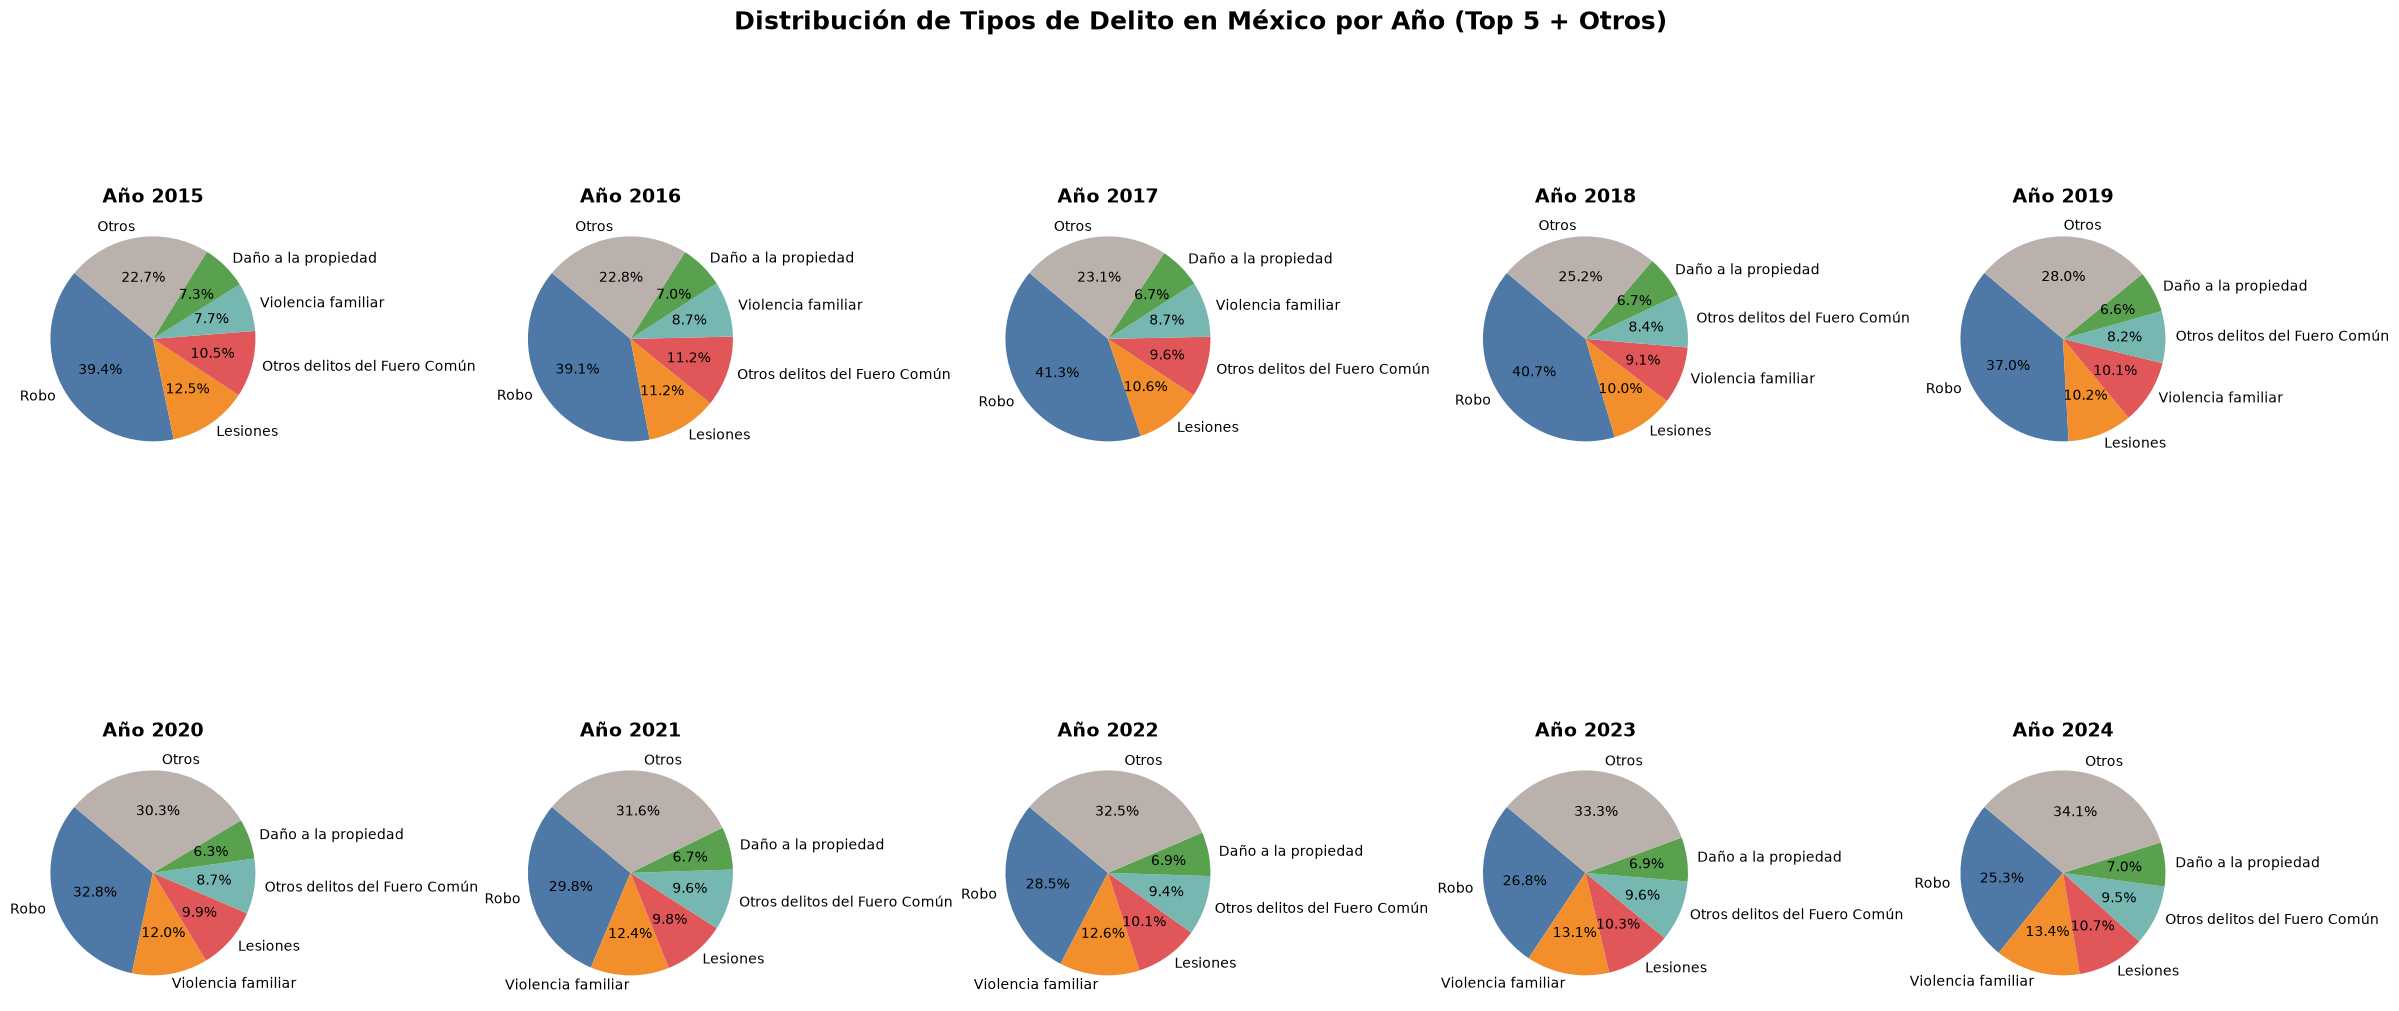

In [5]:
# Ejercicio 3: Gráfica de pastel de tipos de delito para cada año
# Agrupamos los delitos principales (Top 5) y catalogamos el resto como 'Otros' para que sea legible.
years = sorted(df['anio'].unique())

# Configurar cuadrícula de subplots
fig, axes = plt.subplots(2, 5, figsize=(24, 12))
axes = axes.flatten()

colores = ['#4e79a7', '#f28e2b', '#e15759', '#76b7b2', '#59a14f', '#bab0ac']

for i, yr in enumerate(years):
    df_yr = df[df['anio'] == yr]
    crimes_summary = df_yr.groupby('tipo_de_delito')['frecuencia'].sum().reset_index()
    crimes_summary = crimes_summary.sort_values(by='frecuencia', ascending=False)
    
    # Tomamos Top 5 y agrupamos el resto en 'Otros'
    top5 = crimes_summary.head(5)
    others_val = crimes_summary.iloc[5:]['frecuencia'].sum()
    others_df = pd.DataFrame([{'tipo_de_delito': 'Otros', 'frecuencia': others_val}])
    
    plot_data = pd.concat([top5, others_df], ignore_index=True)
    
    # Graficar pastel en el respectivo subplot
    axes[i].pie(
        plot_data['frecuencia'], 
        labels=plot_data['tipo_de_delito'], 
        autopct='%1.1f%%', 
        startangle=140, 
        colors=colores,
        textprops={'fontsize': 10}
    )
    axes[i].set_title(f'Año {yr}', fontsize=14, fontweight='bold')

plt.suptitle('Distribución de Tipos de Delito en México por Año (Top 5 + Otros)', fontsize=18, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()


---
#### Calcula la tasa por 100,000 habitantes
##### Tasa por 100,000 habitantes
Mostrar el total de delitos en una entidad no nos sirve de mucho. Es mucho más útil calcular la tasa de incidencia delictiva por cada 100,000 habitantes

$$
tasa = \frac{delitos\space totales}{población} \times 100,000
$$

Esta tasa la podemos anualizar multiplicándola por un factor de 12
$$
tasa\space anualizada = tasa \times 12
$$

Población por entidad federativa según [la encuesta intercensal 2015](https://www.inegi.org.mx/programas/intercensal/2015/)

No tienes que descargar nada. Ya están los datos en la carpeta data

In [6]:
pobs = pd.read_csv('data/poblacion_entidades_2015.csv', encoding='iso-8859-1', sep=";")
pobs = pobs[['Cve_Entidad', 'Entidad', 'Poblacion']]
pobs = pobs.rename(columns={'Cve_Entidad':'clave_entidad', 'Entidad':'entidad', 'Poblacion':'poblacion'})
pobs.head()

,clave_entidad,entidad,poblacion
0,1,Aguascalientes,1312544.0
1,2,Baja California,3315766.0
2,3,Baja California Sur,712029.0
3,4,Campeche,899931.0
4,5,Coahuila de Zaragoza,5217908.0


In [7]:
# 1. Unir el DataFrame de delitos con el de población
# df tiene 'clave_ent' y pobs tiene 'clave_entidad'
df_tasas = df.merge(pobs, left_on='clave_ent', right_on='clave_entidad')

# Limpiamos columnas redundantes o con sufijos y renombramos para claridad
df_tasas = df_tasas.drop(columns=['clave_entidad', 'entidad_y']).rename(columns={'entidad_x': 'entidad'})

# 2. Calcular la tasa por cada 100,000 habitantes
df_tasas['tasa'] = (df_tasas['frecuencia'] / df_tasas['poblacion']) * 100000

# 3. Anualizar la tasa (multiplicar por 12)
df_tasas['tasa_anualizada'] = df_tasas['tasa'] * 12

print("DataFrame de tasas calculadas:")
display(df_tasas.head())


DataFrame de tasas calculadas:


,anio,clave_ent,entidad,tipo_de_delito,nombre_mes,fecha,frecuencia,poblacion,tasa,tasa_anualizada
0,2015,1,Aguascalientes,Aborto,abril,2015-04-01,0.0,1312544.0,0.000000,0.000000
1,2015,1,Aguascalientes,Aborto,agosto,2015-08-01,0.0,1312544.0,0.000000,0.000000
2,2015,1,Aguascalientes,Aborto,diciembre,2015-12-01,0.0,1312544.0,0.000000,0.000000
3,2015,1,Aguascalientes,Aborto,enero,2015-01-01,0.0,1312544.0,0.000000,0.000000
4,2015,1,Aguascalientes,Aborto,febrero,2015-02-01,3.0,1312544.0,0.228564,2.742765


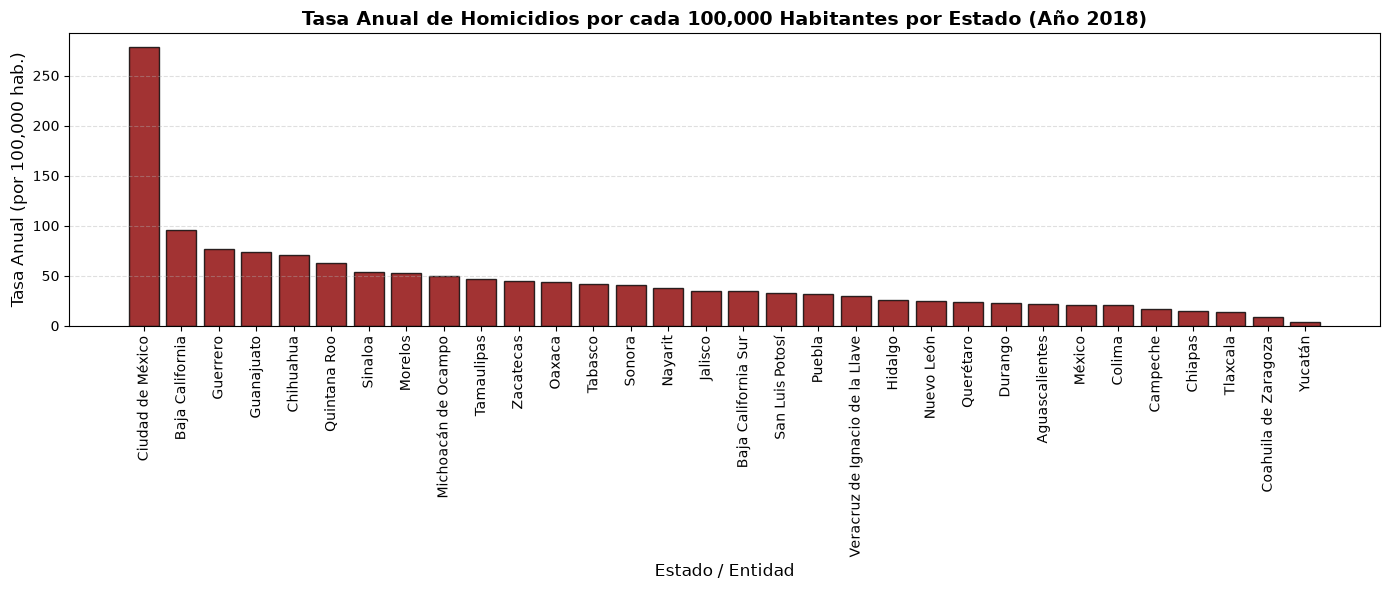

Top 5 de estados con mayor tasa anual de Homicidios en 2018:


,anio,entidad,poblacion,frecuencia,tasa_anual
102,2018,Ciudad de México,711235.0,1979.0,278.248399
97,2018,Baja California,3315766.0,3169.0,95.573692
107,2018,Guerrero,3533251.0,2716.0,76.869716
106,2018,Guanajuato,5853677.0,4298.0,73.423935
101,2018,Chihuahua,2954915.0,2089.0,70.695773


In [8]:
# Vamos a analizar y graficar la tasa anualizada de Homicidios por cada 100,000 habitantes
# agrupando por año y entidad para ver los estados con mayor tasa de homicidios en un año específico (por ejemplo, 2018).
homicidios_tasas = df_tasas[df_tasas['tipo_de_delito'] == 'Homicidio']

# Agrupamos por año, entidad y población para obtener la frecuencia acumulada anual
homicidios_anual = homicidios_tasas.groupby(['anio', 'entidad', 'poblacion'])['frecuencia'].sum().reset_index()

# Calculamos la tasa anual acumulada: (homicidios_totales_anio / poblacion) * 100,000
homicidios_anual['tasa_anual'] = (homicidios_anual['frecuencia'] / homicidios_anual['poblacion']) * 100000

# Ordenar los estados por tasa en el año 2018 de mayor a menor
homicidios_2018 = homicidios_anual[homicidios_anual['anio'] == 2018].sort_values(by='tasa_anual', ascending=False)

# Graficar
plt.figure(figsize=(14, 6))
plt.bar(homicidios_2018['entidad'], homicidios_2018['tasa_anual'], color='darkred', edgecolor='black', alpha=0.8)
plt.title('Tasa Anual de Homicidios por cada 100,000 Habitantes por Estado (Año 2018)', fontsize=14, fontweight='bold')
plt.xlabel('Estado / Entidad', fontsize=12)
plt.ylabel('Tasa Anual (por 100,000 hab.)', fontsize=12)
plt.xticks(rotation=90)
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

# Imprimir el Top 5 de estados con mayor tasa en 2018
print("Top 5 de estados con mayor tasa anual de Homicidios en 2018:")
display(homicidios_2018.head(5))
